In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

ModuleNotFoundError: No module named 'skimage'

In [ ]:
def mostrar(imagens, titulos, cmap='gray', tamanho=4):
  n = len(imagens)
  plt.figure(figsize = (tamanho*n, tamanho))
  for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(imagens[i], cmap = cmap)
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()

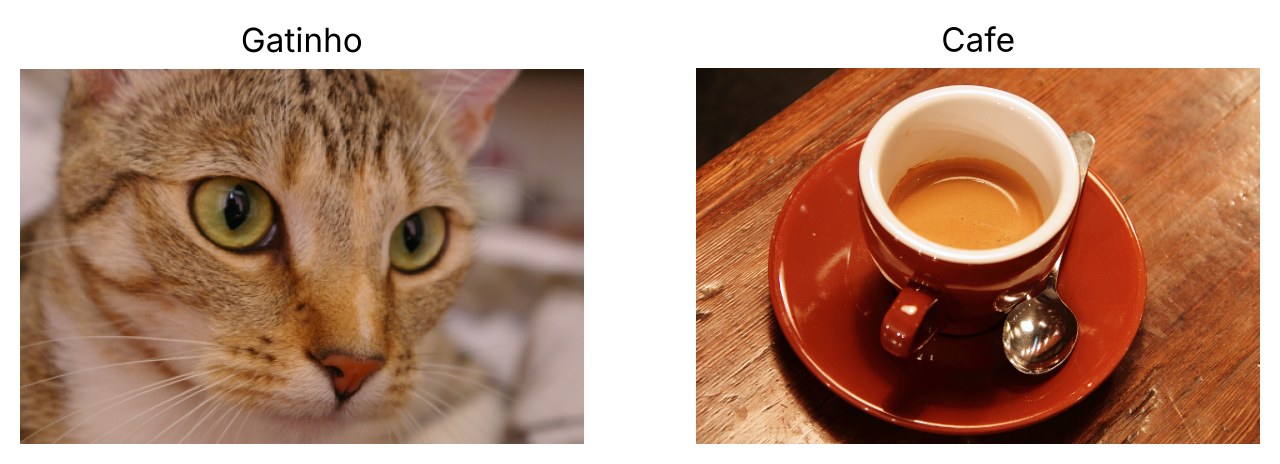

In [ ]:
mostrar([data.cat(), data.coffee()],('Gatinho', 'Cafe') )

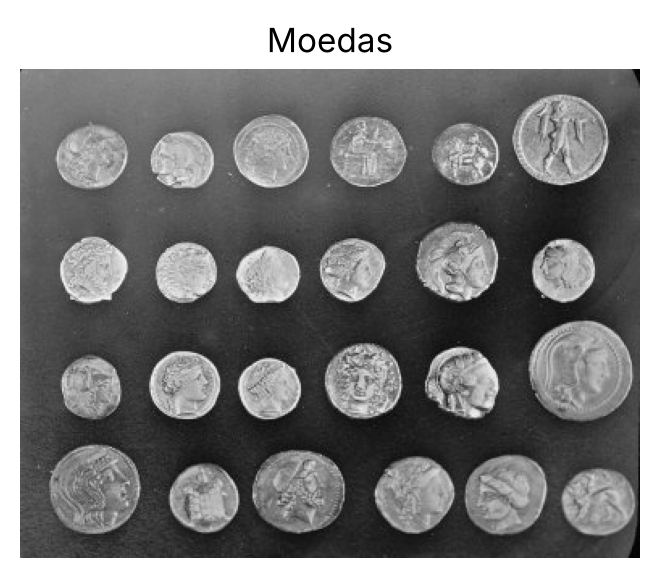

In [ ]:
moedas = data.coins()
mostrar([moedas], ['Moedas'])

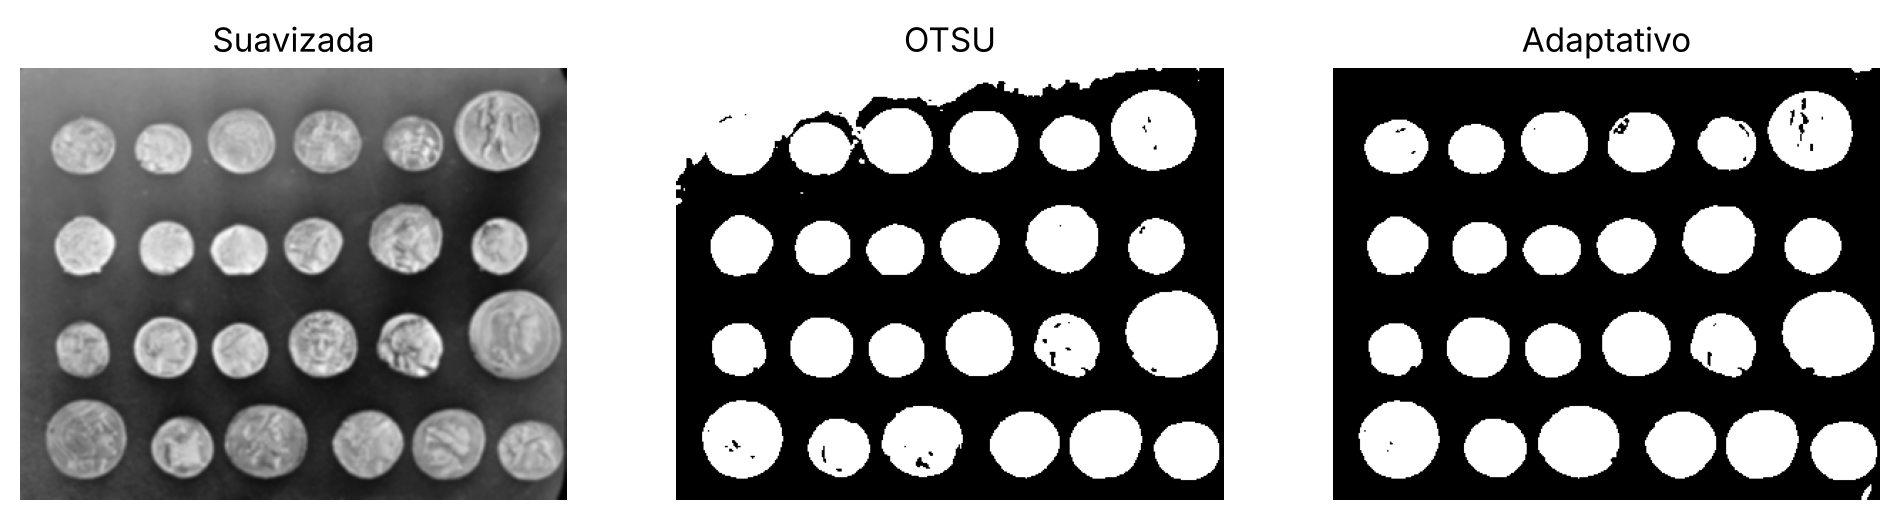

In [ ]:
suave = cv2.GaussianBlur(moedas, (5,5), 0)

_, mascara_otsu = cv2.threshold(suave, 0, 255, cv2.THRESH_OTSU + cv2.THRESH_BINARY) # Iluminação não uniforme fez ficar um pouco ruim
mascara_adapt   = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY,101, -20)

mostrar([suave, mascara_otsu, mascara_adapt],['Suavizada', 'OTSU', 'Adaptativo'])


In [ ]:
contornos, _ = cv2.findContours(mascara_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Filtros contornos pequenos
contornos = [c for c in contornos if cv2.contourArea(c) > 500]

# Cria mascara final a partir dos contornos
mascara_final = np.zeros_like(mascara_adapt)

# Desenha os contornos na mascara final
cv2.drawContours(mascara_final, contornos, -1, 255, thickness = -1)

# Converte imagem original cinza em RGB
moedas_rgb = cv2.cvtColor(moedas, cv2.COLOR_GRAY2RGB)

# Sobrepoe os contornos na imagem original
cv2.drawContours(moedas_rgb, contornos, -1, (255,0,0), 2)

for i, c in enumerate(contornos): # Enumerate retorna uma tupla com os indices
  x, y, w, h = cv2.boundingRect(c)
  cv2.putText(moedas_rgb, str(i + 1), (x, y+15), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 2)
moedas_rgb

array([[[ 47,  47,  47],
        [123, 123, 123],
        [133, 133, 133],
        ...,
        [ 14,  14,  14],
        [  3,   3,   3],
        [ 12,  12,  12]],

       [[ 93,  93,  93],
        [144, 144, 144],
        [145, 145, 145],
        ...,
        [ 12,  12,  12],
        [  7,   7,   7],
        [  7,   7,   7]],

       [[126, 126, 126],
        [147, 147, 147],
        [143, 143, 143],
        ...,
        [  2,   2,   2],
        [ 13,  13,  13],
        [  3,   3,   3]],

       ...,

       [[ 81,  81,  81],
        [ 79,  79,  79],
        [ 74,  74,  74],
        ...,
        [  6,   6,   6],
        [  4,   4,   4],
        [  7,   7,   7]],

       [[ 88,  88,  88],
        [ 82,  82,  82],
        [ 74,  74,  74],
        ...,
        [  5,   5,   5],
        [  7,   7,   7],
        [  8,   8,   8]],

       [[ 91,  91,  91],
        [ 79,  79,  79],
        [ 68,  68,  68],
        ...,
        [  4,   4,   4],
        [ 10,  10,  10],
        [  7,   7,   7]]

## Segmentação por instância

- **Semântica:** cada pixel recebe uma classe (aqui só existe "moeda" × fundo) → todas as moedas ficam com o mesmo valor (255).
- **Instância:** além da classe, cada objeto recebe um **rótulo próprio** (1, 2, 3, ...) → cada moeda vira uma cor diferente.

Aproveitamos os `contornos` já filtrados acima: cada contorno é preenchido na máscara de instâncias com um ID diferente.

In [ ]:
# Ordena os contornos por linha e depois por coluna (só para as cores ficarem em sequência, como na referência)
def chave_ordem(c, altura_linha=60):
  x, y, w, h = cv2.boundingRect(c)
  return ((y + h // 2) // altura_linha, x)

contornos_ord = sorted(contornos, key=chave_ordem)

# Máscara de instâncias: 0 = fundo, 1..N = uma moeda cada
mascara_instancia = np.zeros(moedas.shape, dtype=np.int32)
for i, c in enumerate(contornos_ord):
  cv2.drawContours(mascara_instancia, [c], -1, i + 1, thickness=-1)

print('Moedas encontradas:', mascara_instancia.max())

Moedas encontradas: 24


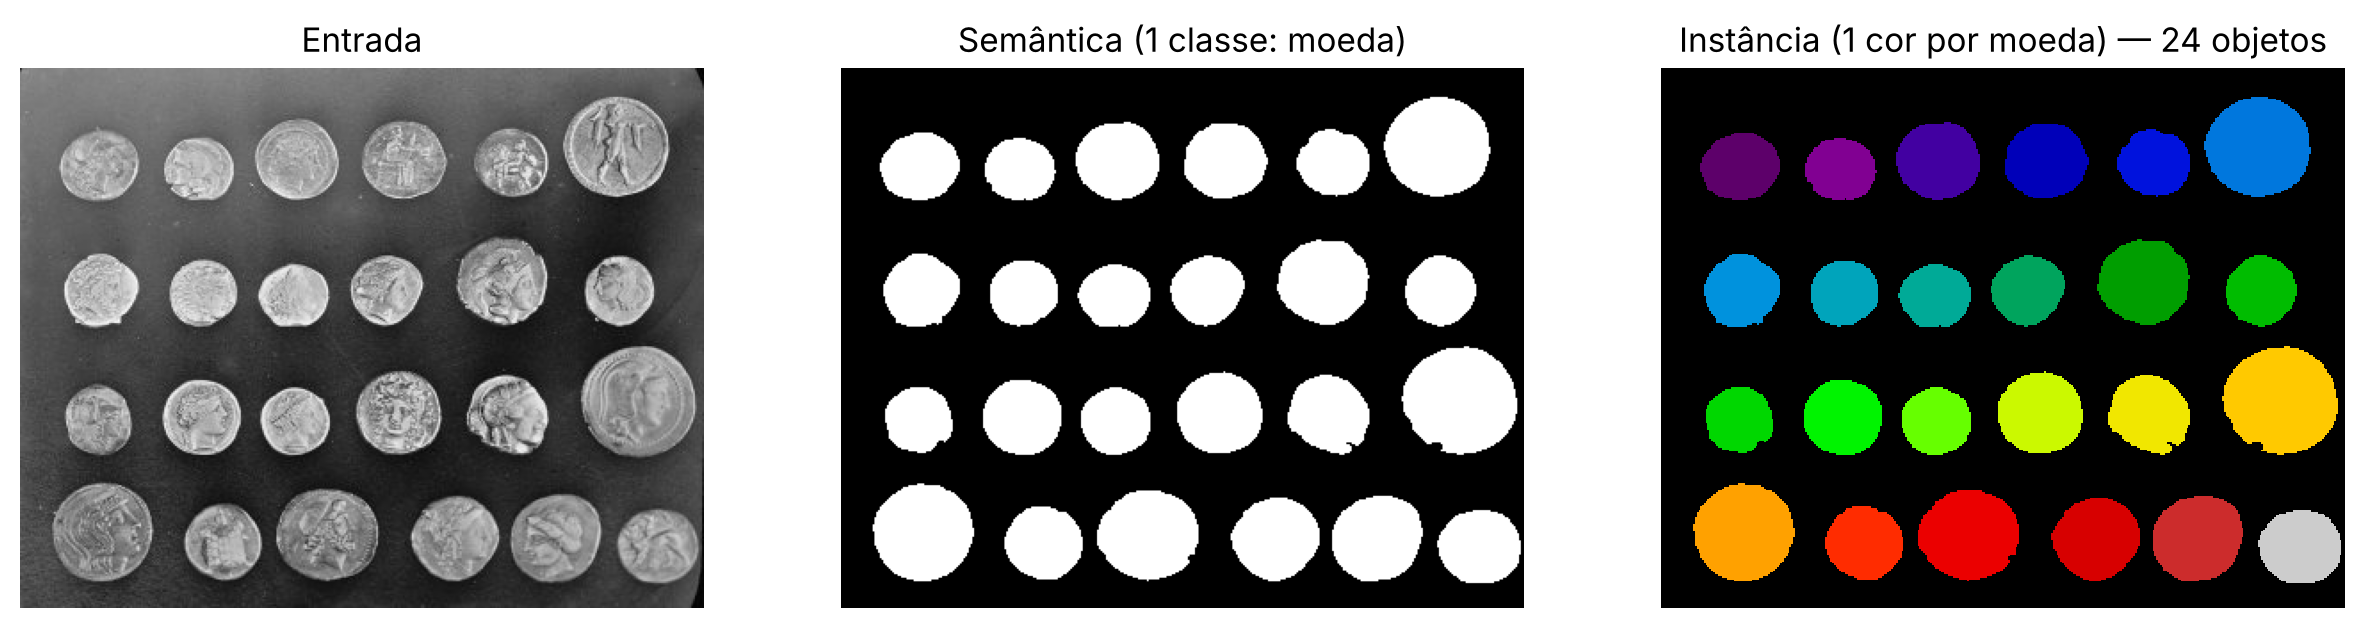

In [ ]:
def plot_comparacao(entrada, semantica, instancia, nome_obj='moeda', cmap_inst='nipy_spectral'):
  fig, ax = plt.subplots(1, 3, figsize=(15, 4))
  ax[0].imshow(entrada, cmap='gray');   ax[0].set_title('Entrada')
  ax[1].imshow(semantica, cmap='gray'); ax[1].set_title(f'Semântica (1 classe: {nome_obj})')
  ax[2].imshow(instancia, cmap=cmap_inst, interpolation='nearest')
  ax[2].set_title(f'Instância (1 cor por {nome_obj}) — {instancia.max()} objetos')
  for a in ax: a.axis('off')
  plt.show()

plot_comparacao(moedas, mascara_final, mascara_instancia)

## Teste com outra imagem: `data.hubble_deep_field()`

Mesmo pipeline (suavização → limiar adaptativo → contornos → filtro de área → rótulos), agora numa foto do telescópio Hubble com estrelas e galáxias.
Encapsulamos tudo numa função para reaproveitar.

In [ ]:
def segmentar(img_gray, area_min=500, bloco=101, C=-20):
  suave = cv2.GaussianBlur(img_gray, (5, 5), 0)
  mascara = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, bloco, C)

  conts, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
  conts = [c for c in conts if cv2.contourArea(c) > area_min]
  conts = sorted(conts, key=chave_ordem)

  semantica = np.zeros_like(mascara)
  cv2.drawContours(semantica, conts, -1, 255, thickness=-1)

  instancia = np.zeros(mascara.shape, dtype=np.int32)
  for i, c in enumerate(conts):
    cv2.drawContours(instancia, [c], -1, i + 1, thickness=-1)
  return semantica, instancia

# Colormap com cores aleatórias (fundo preto): com centenas de objetos, cores sequenciais
# deixam vizinhos quase iguais; cores embaralhadas separam melhor as instâncias.
from matplotlib.colors import ListedColormap
def cmap_aleatorio(n, seed=0):
  cores = np.random.default_rng(seed).uniform(0.2, 1.0, (n + 1, 3))
  cores[0] = 0
  return ListedColormap(cores)

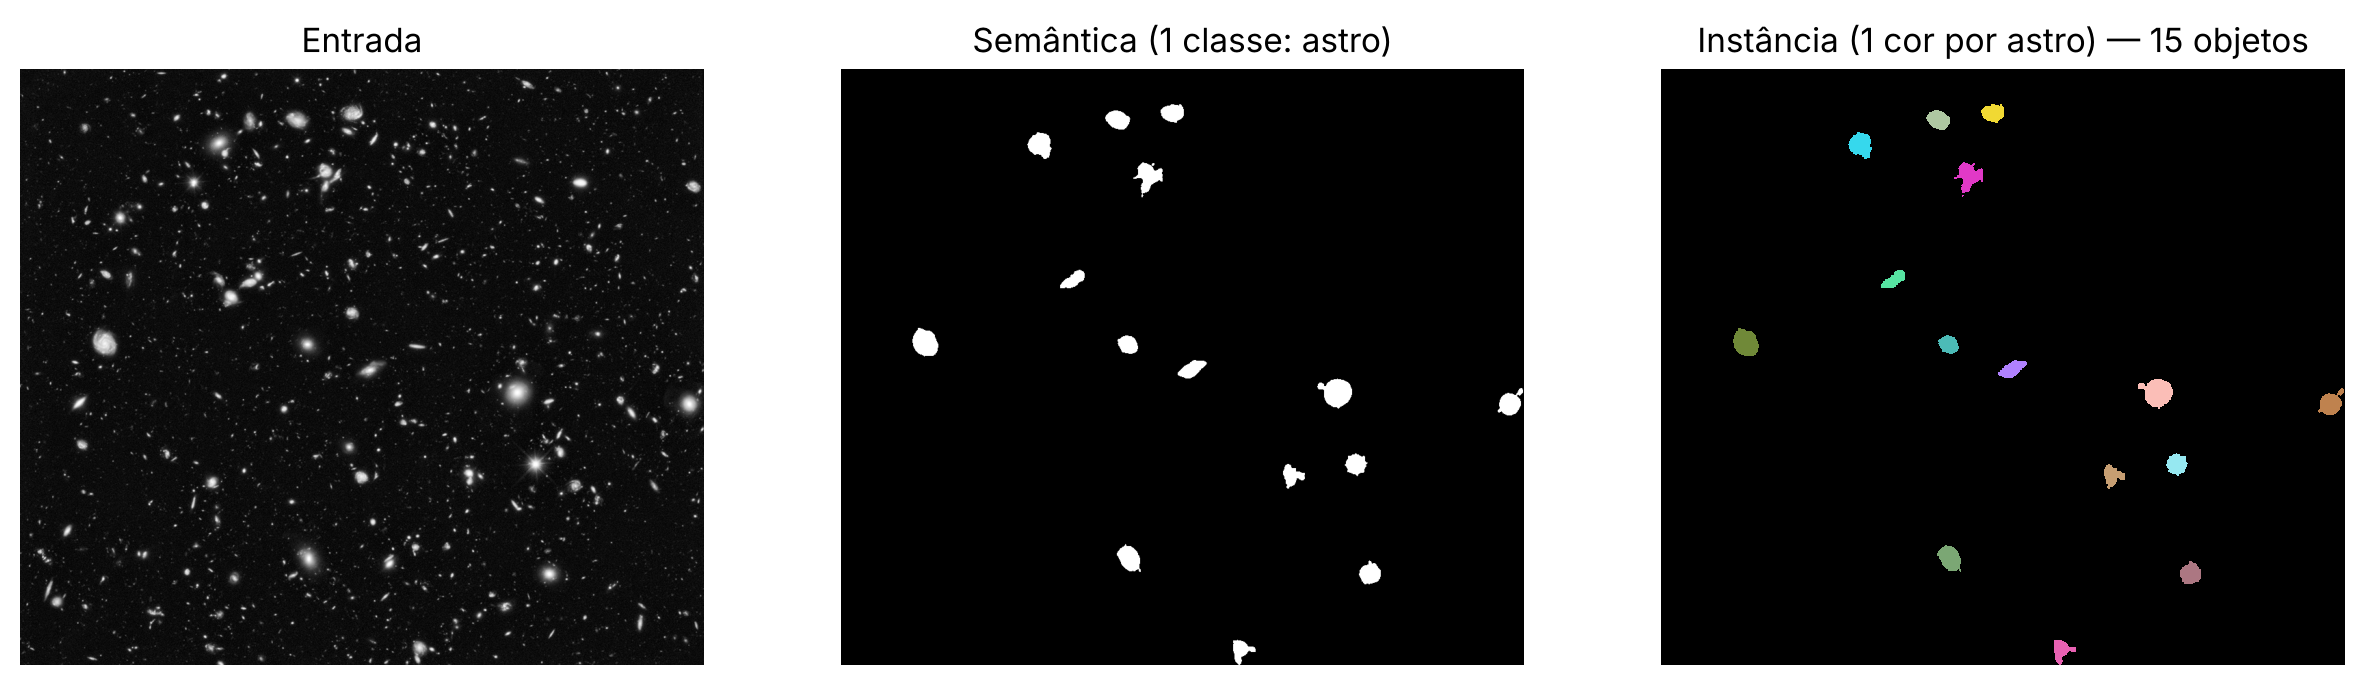

In [ ]:
hubble = cv2.cvtColor(data.hubble_deep_field(), cv2.COLOR_RGB2GRAY)

# 1) Exatamente os mesmos parâmetros das moedas (area_min = 500)
sem_h, inst_h = segmentar(hubble, area_min=500)
plot_comparacao(hubble, sem_h, inst_h, nome_obj='astro', cmap_inst=cmap_aleatorio(inst_h.max()))

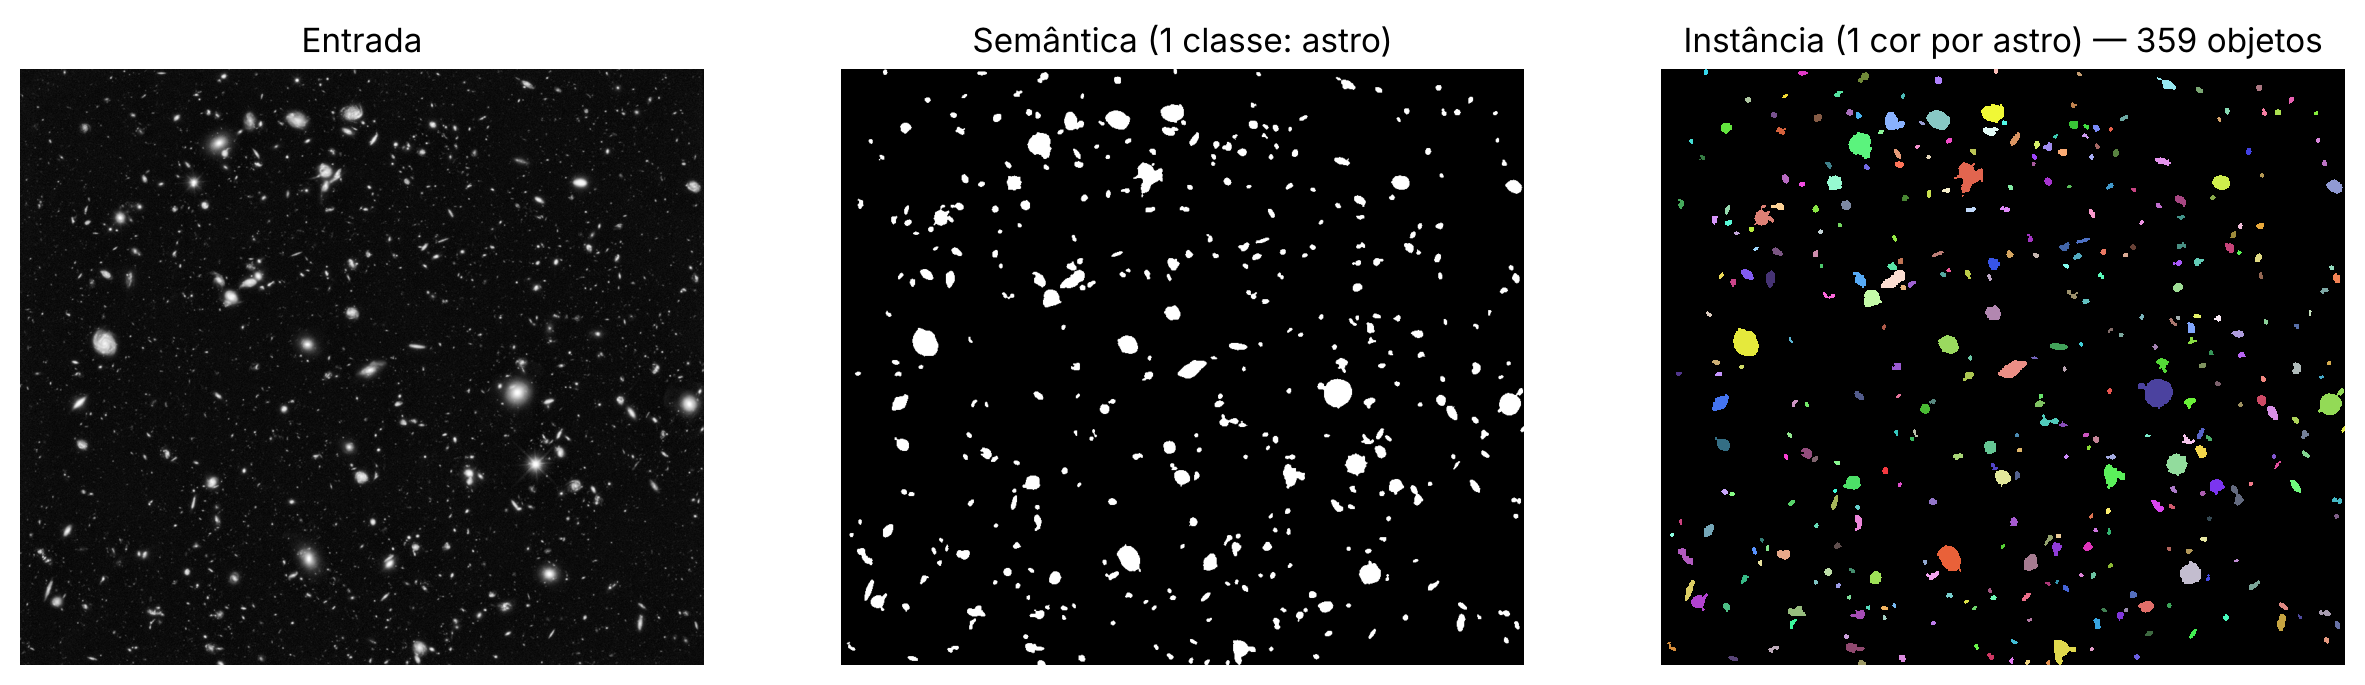

In [ ]:
# 2) Filtro de área ajustado para a escala dos objetos (estrelas/galáxias são bem menores que moedas)
sem_h, inst_h = segmentar(hubble, area_min=20)
plot_comparacao(hubble, sem_h, inst_h, nome_obj='astro', cmap_inst=cmap_aleatorio(inst_h.max()))

### Houve diferença?

Sim.

- **Moedas:** objetos grandes, de tamanho parecido e bem separados. Cada contorno é exatamente uma moeda, então a máscara de instâncias sai limpa (24 moedas, uma cor cada).
- **Hubble:** com os mesmos parâmetros, o filtro `area > 500` descarta quase tudo e sobram só as maiores galáxias (15 objetos). Ajustando a área mínima para 20, aparecem centenas de objetos, mas surgem dois problemas: **galáxias encostadas viram uma única instância** (contornos externos não separam objetos que se tocam) e **ruído/pontos minúsculos** passam a ser contados.
- **Conclusão:** separar instâncias por contornos funciona bem quando os objetos não se tocam e têm escala conhecida, como nas moedas. Em cenas densas e com tamanhos variados, como o Hubble, os parâmetros precisam ser ajustados à imagem, e objetos colados exigiriam algo como **watershed com transformada de distância** para serem separados.